# Imports and Configuration

In [99]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
pl.Config.set_tbl_rows(-1)
pl.Config.set_tbl_cols(-1)

polars.config.Config

# Loading the dataset

In [100]:
files = Path("../data/raw").glob("*.csv")
dfs = []

for file in files:
    df = pl.read_csv(file, null_values=["NaN", "nan", "Infinity", "infinity", "INF", "inf"])
    df = df.rename({c: c.strip() for c in df.columns})
    dfs.append(df)

data = pl.concat(dfs)

# Data Ingestion: Downcast Types & Save to Parquet

In [101]:
data.write_parquet("../data/processed/cicids2017.parquet")

In [102]:
data = pl.read_parquet("../data/processed/cicids2017.parquet")

In [103]:
data = data.with_columns(pl.col(pl.Float64()).cast(pl.Float32()))

In [104]:
data = data.with_columns(pl.col(pl.Int64()).cast(pl.Int32()))

# Data Exploration

* Adding `IsAttack` feature 

In [105]:
data = data.with_columns(
    (pl.col("Label") == "BENIGN").cast(pl.Int32).alias("IsBenign")
)

* Shape

In [106]:
data.shape

(2100814, 85)

* We got 2,100,814 rows (records) and 85 columns (features) 

In [107]:
data.head()

Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Fwd Segment Size Avg,Bwd Segment Size Avg,Fwd Bytes/Bulk Avg,Fwd Packet/Bulk Avg,Fwd Bulk Rate Avg,Bwd Bytes/Bulk Avg,Bwd Packet/Bulk Avg,Bwd Bulk Rate Avg,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,FWD Init Win Bytes,Bwd Init Win Bytes,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,IsBenign
str,str,i32,str,i32,i32,str,i32,i32,i32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,i32,i32,i32,i32,i32,i32,f32,f32,f32,f32,f32,f32,f32,i32,i32,i32,i32,i32,i32,i32,i32,f32,f32,f32,f32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,f32,f32,f32,f32,f32,f32,f32,f32,str,i32
"""192.168.10.50-192.168.10.3-561…","""192.168.10.50""",56108,"""192.168.10.3""",3268,6,"""07/07/2017 01:59:50 PM""",112740690,32,16,6448.0,1152.0,403.0,0.0,201.5,204.724197,72.0,72.0,72.0,0.0,67.411331,0.425756,2.398738e6,5.798698e6,1.6399772e7,3.0,1.12740688e8,3636796.5,6.848761e6,1.6399772e7,3.0,1.12740352e8,7.516023e6,8.323385e6,1.640011e7,3.0,16,16,0,0,1024,512,0.283837,0.141919,0.0,403.0,158.333328,177.341751,31450.099609,0,0,0,32,48,0,0,0,0.5,158.333328,201.5,72.0,0,0,0,0,0,0,0,134,0,24,377,2079,15,32,359.428558,11.998015,380.0,343.0,1.6105402e7,498804.8125,1.6399772e7,1.5375229e7,"""BENIGN""",1
"""192.168.10.50-192.168.10.3-421…","""192.168.10.50""",42144,"""192.168.10.3""",389,6,"""07/07/2017 01:59:50 PM""",112740560,32,16,6448.0,5056.0,403.0,0.0,201.5,204.724197,316.0,316.0,316.0,0.0,102.039589,0.425756,2.3987e6,5798709.5,1.6399782e7,2.0,1.1274056e8,3.6368e6,6.848777e6,1.6399782e7,2.0,1.1274024e8,7.516016e6,8.323376e6,1.640011e7,4.0,16,16,0,0,1024,512,0.283837,0.141919,0.0,403.0,239.666672,174.984177,30619.460938,0,0,0,32,48,0,0,0,0.5,239.666672,201.5,316.0,0,0,0,0,0,0,0,134,0,105,955,2079,15,32,320.285706,15.744991,330.0,285.0,1.6105427e7,498793.65625,1.6399782e7,1.5375263e7,"""BENIGN""",1
"""8.6.0.1-8.0.6.4-0-0-0""","""8.6.0.1""",0,"""8.0.6.4""",0,0,"""07/07/2017 02:00:31 PM""",113757377,545,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.790898,209112.828125,1.3955e6,2.075703e7,0.0,1.13757376e8,209112.828125,1.3955e6,2.075703e7,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,4.790898,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,9.361829e6,7.324646e6,1.8851792e7,19.0,1.2210358e7,6.935824e6,2.075703e7,5.504997e6,"""BENIGN""",1
"""192.168.10.25-224.0.0.251-5353…","""192.168.10.25""",5353,"""224.0.0.251""",5353,17,"""07/07/2017 02:00:42 PM""",91997219,388,0,37151.0,0.0,227.0,37.0,95.75,55.78532,0.0,0.0,0.0,0.0,403.827423,4.217519,237718.90625,1.5116e6,1.9776792e7,0.0,9.1997216e7,237718.90625,1.5116e6,1.9776792e7,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,3104,0,4.217519,0.0,37.0,227.0,95.75,55.78532,3112.001953,0,0,0,0,0,0,0,0,0.0,95.75,95.75,0.0,1857,19,9453,0,0,0,1,95,0,0,0,0,387,8,9.801664e6,1.1527818e7,2.4721964e7,16.0,1.3197637e7,5826904.5,1.9776792e7,5.81747e6,"""BENIGN""",1
"""192.168.10.25-17.253.14.125-12…","""192.168.10.25""",123,"""17.253.14.125""",123,17,"""07/07/

In [108]:
data.columns

['Flow ID',
 'Src IP',
 'Src Port',
 'Dst IP',
 'Dst Port',
 'Protocol',
 'Timestamp',
 'Flow Duration',
 'Total Fwd Packet',
 'Total Bwd packets',
 'Total Length of Fwd Packet',
 'Total Length of Bwd Packet',
 'Fwd Packet Length Max',
 'Fwd Packet Length Min',
 'Fwd Packet Length Mean',
 'Fwd Packet Length Std',
 'Bwd Packet Length Max',
 'Bwd Packet Length Min',
 'Bwd Packet Length Mean',
 'Bwd Packet Length Std',
 'Flow Bytes/s',
 'Flow Packets/s',
 'Flow IAT Mean',
 'Flow IAT Std',
 'Flow IAT Max',
 'Flow IAT Min',
 'Fwd IAT Total',
 'Fwd IAT Mean',
 'Fwd IAT Std',
 'Fwd IAT Max',
 'Fwd IAT Min',
 'Bwd IAT Total',
 'Bwd IAT Mean',
 'Bwd IAT Std',
 'Bwd IAT Max',
 'Bwd IAT Min',
 'Fwd PSH Flags',
 'Bwd PSH Flags',
 'Fwd URG Flags',
 'Bwd URG Flags',
 'Fwd Header Length',
 'Bwd Header Length',
 'Fwd Packets/s',
 'Bwd Packets/s',
 'Packet Length Min',
 'Packet Length Max',
 'Packet Length Mean',
 'Packet Length Std',
 'Packet Length Variance',
 'FIN Flag Count',
 'SYN Flag Count',
 'R

In [109]:
data.glimpse()

Rows: 2100814
Columns: 85
$ Flow ID                    <str> '192.168.10.50-192.168.10.3-56108-3268-6', '192.168.10.50-192.168.10.3-42144-389-6', '8.6.0.1-8.0.6.4-0-0-0', '192.168.10.25-224.0.0.251-5353-5353-17', '192.168.10.25-17.253.14.125-123-123-17', '192.168.10.5-192.168.10.3-123-123-17', '192.168.10.5-192.168.10.3-49159-445-6', '192.168.10.5-134.170.115.55-49176-443-6', '192.168.10.9-192.168.10.3-123-123-17', '192.168.10.14-192.168.10.3-49414-445-6'
$ Src IP                     <str> '192.168.10.50', '192.168.10.50', '8.6.0.1', '192.168.10.25', '192.168.10.25', '192.168.10.5', '192.168.10.5', '192.168.10.5', '192.168.10.9', '192.168.10.14'
$ Src Port                   <i32> 56108, 42144, 0, 5353, 123, 123, 49159, 49176, 123, 49414
$ Dst IP                     <str> '192.168.10.3', '192.168.10.3', '8.0.6.4', '224.0.0.251', '17.253.14.125', '192.168.10.3', '192.168.10.3', '134.170.115.55', '192.168.10.3', '192.168.10.3'
$ Dst Port                   <i32> 3268, 389, 0, 5353, 123, 12

In [110]:
data.to_pandas().info()

<class 'pandas.DataFrame'>
RangeIndex: 2100814 entries, 0 to 2100813
Data columns (total 85 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   Flow ID                     str    
 1   Src IP                      str    
 2   Src Port                    int32  
 3   Dst IP                      str    
 4   Dst Port                    int32  
 5   Protocol                    int32  
 6   Timestamp                   str    
 7   Flow Duration               int32  
 8   Total Fwd Packet            int32  
 9   Total Bwd packets           int32  
 10  Total Length of Fwd Packet  float32
 11  Total Length of Bwd Packet  float32
 12  Fwd Packet Length Max       float32
 13  Fwd Packet Length Min       float32
 14  Fwd Packet Length Mean      float32
 15  Fwd Packet Length Std       float32
 16  Bwd Packet Length Max       float32
 17  Bwd Packet Length Min       float32
 18  Bwd Packet Length Mean      float32
 19  Bwd Packet Length Std       floa

## Checking Duplicated rows

In [111]:
data.is_duplicated().sum() / 2

3143.0

* We got 3,143 duplicated records that need to be deleted

## Identifying missing values

In [112]:
data.null_count().sum()

Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Fwd Segment Size Avg,Bwd Segment Size Avg,Fwd Bytes/Bulk Avg,Fwd Packet/Bulk Avg,Fwd Bulk Rate Avg,Bwd Bytes/Bulk Avg,Bwd Packet/Bulk Avg,Bwd Bulk Rate Avg,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,FWD Init Win Bytes,Bwd Init Win Bytes,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,IsBenign
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,793,793,252,252,252,252,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [113]:
data.to_pandas().isnull().sum()

Flow ID     0
Src IP      0
Src Port    0
Dst IP      0
Dst Port    0
           ..
Idle Std    0
Idle Max    0
Idle Min    0
Label       0
IsBenign    0
Length: 85, dtype: int64

* We got 6 features, which are `Flow Bytes/s`, `Flow Packets/s`, `Flow IAT Mean`, `Flow IAT Std`, `Flow IAT Max` and `Flow IAT Min`, that have missing and infinite values

* `Flow Bytes/s` and `Flow Packets/s` has infinite values which needs to be handled by dropping as it enhances data integrity, ensures statistical accuracy, aids in proper model training, and clarifies insights.

# Data Cleaning 

#  Dropping useless features

In [114]:
data = data.drop(['Flow ID', 'Src IP', 'Dst IP', 'Timestamp','Src Port','Dst Port'])

## Duplicates

In [115]:
data.is_duplicated().sum()

450353

* Notice that more duplicates appeared after dropping unnecessary columns

In [116]:
data = data.unique(keep="first", maintain_order=True)

In [117]:
data.is_duplicated().sum()

0

## Infinite and missing values

In [118]:
# Calculating Label counts before dropping
attack_counts = (
    data.group_by("Label")
    .len(name="Number of Occurrences")
    .rename({"Label": "Attack Type"})
)

# Dataframe with no missing values
data_no_na = data.drop_nulls()

# Calculating Label counts after dropping
occurrences_nonull = (
    data_no_na.group_by("Label")
    .len(name="Occurrences w/o Null Rows")
    .rename({"Label": "Attack Type"})
)

# Merging both dataframes and calculating the difference
attack_counts = (
    attack_counts.join(occurrences_nonull, on="Attack Type", how="left")
    .with_columns(
        # Fill with 0 in case a specific attack type was entirely wiped out by the drop
        pl.col("Occurrences w/o Null Rows").fill_null(0) 
    )
    .with_columns(
        (pl.col("Number of Occurrences") - pl.col("Occurrences w/o Null Rows")).alias("Abs Difference")
    )
    .with_columns(
        ((pl.col("Abs Difference") * 100) / pl.col("Number of Occurrences")).round(2).alias("Difference %")
    )
)


attack_counts

Attack Type,Number of Occurrences,Occurrences w/o Null Rows,Abs Difference,Difference %
str,u32,u32,u32,f64
"""Heartbleed""",11,11,0,0.0
"""Bot""",738,738,0,0.0
"""DoS slowloris - Attempted""",1704,1703,1,0.06
"""DoS Slowhttptest - Attempted""",3362,3361,1,0.03
"""Infiltration - Attempted""",16,16,0,0.0
"""BENIGN""",1429945,1429893,52,0.0
"""SSH-Patator - Attempted""",8,8,0,0.0
"""Web Attack - XSS - Attempted""",652,652,0,0.0
"""SSH-Patator""",2980,2980,0,0.0


* We notice that the difference after dropping missing values is so low so we'll drop them

In [119]:
data = data.drop_nulls()

In [120]:
data.null_count().sum()

Protocol,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Fwd Segment Size Avg,Bwd Segment Size Avg,Fwd Bytes/Bulk Avg,Fwd Packet/Bulk Avg,Fwd Bulk Rate Avg,Bwd Bytes/Bulk Avg,Bwd Packet/Bulk Avg,Bwd Bulk Rate Avg,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,FWD Init Win Bytes,Bwd Init Win Bytes,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,IsBenign
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


* Great! Now our data neither has missing nor infinite values

## Handling impossible negatives

In [121]:

attack_counts = (
    data.group_by("Label")
    .len(name="Number of Occurrences")
    .rename({"Label": "Attack Type"})
)


window_cols = ['FWD Init Win Bytes', 'Bwd Init Win Bytes']

data_no_neg = data.with_columns(
    pl.when(pl.col(window_cols) == -1)
    .then(None)
    .otherwise(pl.col(window_cols))
    .name.keep()
)

data_no_neg = data.filter(
    ~pl.any_horizontal((pl.selectors.numeric() < 0).fill_null(False))
)


occurrences_nonneg = (
    data_no_neg.group_by("Label")
    .len(name="Occurrences w/o neg Rows")
    .rename({"Label": "Attack Type"})
)


attack_counts = (
    attack_counts.join(occurrences_nonneg, on="Attack Type", how="left")
    .with_columns(

        pl.col("Occurrences w/o neg Rows").fill_null(0) 
    )
    .with_columns(
        (pl.col("Number of Occurrences") - pl.col("Occurrences w/o neg Rows")).alias("Abs Difference")
    )
    .with_columns(
        ((pl.col("Abs Difference") * 100) / pl.col("Number of Occurrences")).round(2).alias("Difference %")
    )
)


attack_counts

Attack Type,Number of Occurrences,Occurrences w/o neg Rows,Abs Difference,Difference %
str,u32,u32,u32,f64
"""Heartbleed""",11,7,4,36.36
"""SSH-Patator - Attempted""",8,8,0,0.0
"""Web Attack - Brute Force - Att…",1214,1214,0,0.0
"""DDoS""",95123,95098,25,0.03
"""DoS Hulk - Attempted""",573,573,0,0.0
"""Infiltration""",32,31,1,3.12
"""DoS GoldenEye - Attempted""",77,77,0,0.0
"""FTP-Patator""",3973,3969,4,0.1
"""DoS slowloris - Attempted""",1703,1703,0,0.0


In [122]:
window_cols = ['FWD Init Win Bytes', 'Bwd Init Win Bytes']

data = data.with_columns(
    pl.when(pl.col(window_cols) == -1)
    .then(None)
    .otherwise(pl.col(window_cols))
    .name.keep()
)

data = data.filter(
    ~pl.any_horizontal((pl.selectors.numeric() < 0).fill_null(False))
)

In [123]:
negative_counts = (
    data
    .select([
        (pl.col(c) < 0).sum().alias(c)
        for c in data.select(pl.selectors.numeric()).columns
    ])
)

negative_counts

Protocol,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Fwd Segment Size Avg,Bwd Segment Size Avg,Fwd Bytes/Bulk Avg,Fwd Packet/Bulk Avg,Fwd Bulk Rate Avg,Bwd Bytes/Bulk Avg,Bwd Packet/Bulk Avg,Bwd Bulk Rate Avg,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,FWD Init Win Bytes,Bwd Init Win Bytes,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,IsBenign
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


# EDA

* Label Value Counts

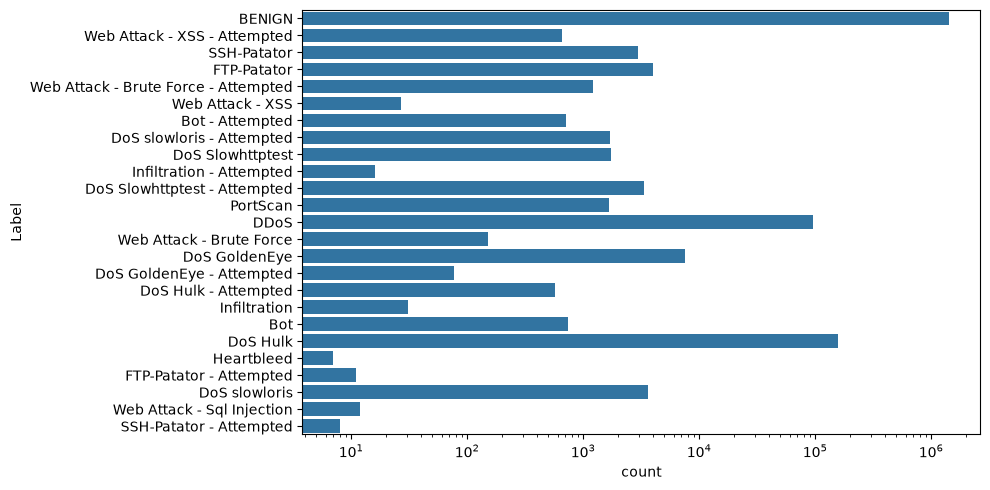

In [124]:
counts = data["Label"].value_counts()
counts.columns = ["Label", "count"]
counts = counts.to_pandas()
plt.figure(figsize=(10,5))
sns.barplot(data = counts, x ="count", y ="Label")
plt.xscale("log")
plt.tight_layout()
plt.show()

In [125]:
data["Label"].value_counts()

Label,count
str,u32
"""DDoS""",95098
"""Web Attack - Brute Force""",151
"""DoS GoldenEye""",7562
"""SSH-Patator""",2978
"""Web Attack - Sql Injection""",12
"""DoS Hulk - Attempted""",573
"""Heartbleed""",7
"""Web Attack - Brute Force - Att…",1214
"""DoS Slowhttptest - Attempted""",3361


## Descriptive Statistics

In [126]:
data.describe()

statistic,Protocol,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Fwd Segment Size Avg,Bwd Segment Size Avg,Fwd Bytes/Bulk Avg,Fwd Packet/Bulk Avg,Fwd Bulk Rate Avg,Bwd Bytes/Bulk Avg,Bwd Packet/Bulk Avg,Bwd Bulk Rate Avg,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,FWD Init Win Bytes,Bwd Init Win Bytes,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,IsBenign
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64
"""count""",1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,1.711447e6,"""1711447""",1.711447e6
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""0""",0.0
"""mean""",11.407645,1.5155e7,8.983222,9.117362,677.89502,8970.698242,252.802841,22.145554,57.071537,74.177353,1498.104736,58.018612,493.734406,574.650269,265978.34375,3295.284668,1.1152e6,2.0926e6,5.996553e6,120517.671875,1.5070596e7,2.482032e6,1.6809e6,5.959203e6,1.481356e6,1.4173984e7,2545382.5,1.5033e6,5351696.5,1.5438e6,1.688353,1.949431,0.000366,0.000001,217.249813,225.604049,1830.019897,1465.264648,21.728846,1543.899048,252.99646,460.812622,712047.375,0.826317,0.995097,0.39033,3.637784,15.391403,0.000367,0.000545,0.000894,0.911788,252.99646,57.071537,493.734406,84.821706,0.261255,90947.277726,3549.847327,1.921104,3.0628e6,0.009078,29.405775,0.000017,222.921988,10810.627104,915.856542,2.583845,16.193651,153359.734375,72434.0,275538.78125,111833.960938,5.400982e6,353647.8125,5.698361e6,5.049901e6,null,0.833954
"""std""",5.507641,3.3634e7,95.483501,132.243994,11483.685547,322128.03125,533.268555,36.388229,99.05761,168.563858,2408.45874,77.23999,714.44989,1039.677612,2.1535e6,19935.054688,4417393.5,6.647464e6,1.573166e7,2.5295e6,3.3617236e7,1.072646e7,4653744.5,1.5733603e7,1.0474556e7,3.3332234e7,1.0726305e7,4.966634e6,1.5424367e7,1.0288539e7,8.839582,8.72517

In [127]:
data.shape

(1711447, 79)

In [128]:
data.head()

Protocol,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Fwd Segment Size Avg,Bwd Segment Size Avg,Fwd Bytes/Bulk Avg,Fwd Packet/Bulk Avg,Fwd Bulk Rate Avg,Bwd Bytes/Bulk Avg,Bwd Packet/Bulk Avg,Bwd Bulk Rate Avg,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,FWD Init Win Bytes,Bwd Init Win Bytes,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,IsBenign
i32,i32,i32,i32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,i32,i32,i32,i32,i32,i32,f32,f32,f32,f32,f32,f32,f32,i32,i32,i32,i32,i32,i32,i32,i32,f32,f32,f32,f32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,f32,f32,f32,f32,f32,f32,f32,f32,str,i32
6,112740690,32,16,6448.0,1152.0,403.0,0.0,201.5,204.724197,72.0,72.0,72.0,0.0,67.411331,0.425756,2.398738e6,5.798698e6,1.6399772e7,3.0,1.12740688e8,3636796.5,6.848761e6,1.6399772e7,3.0,1.12740352e8,7.516023e6,8.323385e6,1.640011e7,3.0,16,16,0,0,1024,512,0.283837,0.141919,0.0,403.0,158.333328,177.341751,31450.099609,0,0,0,32,48,0,0,0,0.5,158.333328,201.5,72.0,0,0,0,0,0,0,0,134,0,24,377,2079,15,32,359.428558,11.998015,380.0,343.0,1.6105402e7,498804.8125,1.6399772e7,1.5375229e7,"""BENIGN""",1
6,112740560,32,16,6448.0,5056.0,403.0,0.0,201.5,204.724197,316.0,316.0,316.0,0.0,102.039589,0.425756,2.3987e6,5798709.5,1.6399782e7,2.0,1.1274056e8,3.6368e6,6.848777e6,1.6399782e7,2.0,1.1274024e8,7.516016e6,8.323376e6,1.640011e7,4.0,16,16,0,0,1024,512,0.283837,0.141919,0.0,403.0,239.666672,174.984177,30619.460938,0,0,0,32,48,0,0,0,0.5,239.666672,201.5,316.0,0,0,0,0,0,0,0,134,0,105,955,2079,15,32,320.285706,15.744991,330.0,285.0,1.6105427e7,498793.65625,1.6399782e7,1.5375263e7,"""BENIGN""",1
0,113757377,545,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.790898,209112.828125,1.3955e6,2.075703e7,0.0,1.13757376e8,209112.828125,1.3955e6,2.075703e7,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,4.790898,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,9.361829e6,7.324646e6,1.8851792e7,19.0,1.2210358e7,6.935824e6,2.075703e7,5.504997e6,"""BENIGN""",1
17,91997219,388,0,37151.0,0.0,227.0,37.0,95.75,55.78532,0.0,0.0,0.0,0.0,403.827423,4.217519,237718.90625,1.5116e6,1.9776792e7,0.0,9.1997216e7,237718.90625,1.5116e6,1.9776792e7,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,3104,0,4.217519,0.0,37.0,227.0,95.75,55.78532,3112.001953,0,0,0,0,0,0,0,0,0.0,95.75,95.75,0.0,1857,19,9453,0,0,0,1,95,0,0,0,0,387,8,9.801664e6,1.1527818e7,2.4721964e7,16.0,1.3197637e7,5826904.5,1.9776792e7,5.81747e6,"""BENIGN""",1
17,66966070,6,6,288.0,288.0,48.0,48.0,48.0,0.0,48.0,48.0,48.0,0.0,8.601371,0.179195,6087824.5,1.9538234e7,6.4974432e7,191.0,6.6942604e7,1.3388521e7,2.8861552e7,6.499774e7,23560.0,6.6942656e7,1.3388531e7,2.8861632e7,6.4997896e7,23604.0,0,0,0,0,48,48,0.089598,0.089598,48.0,48.0,48.0,0.0,0.0,0,0,0,0,0,0,0,0,1.0,48.0,48.0,48.0,0,0,0,0,0,0,0,24,0,24,0,0,5,8,1.968172e6,0.0,1.968172e6,1.968172e6,6.4974432e7,0.0,6.4974432e7,6.4974432e7,"""BENIGN""",1


* IsBenign count plot

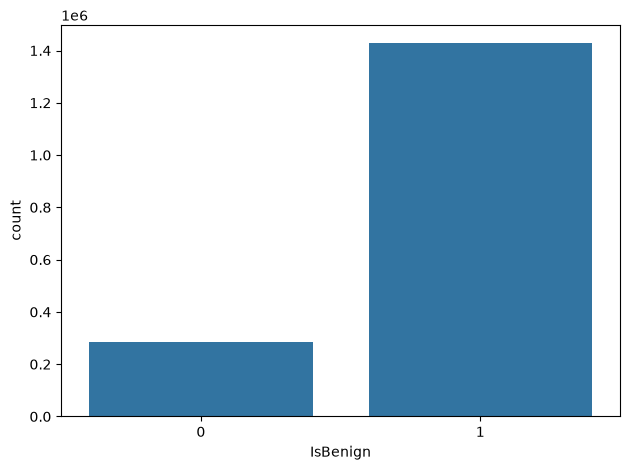

In [129]:
counts = data["IsBenign"].value_counts()
counts = counts.to_pandas()
sns.barplot(data = counts,x = "IsBenign", y= "count")
plt.tight_layout()
plt.show() 

## Correlation Analysis

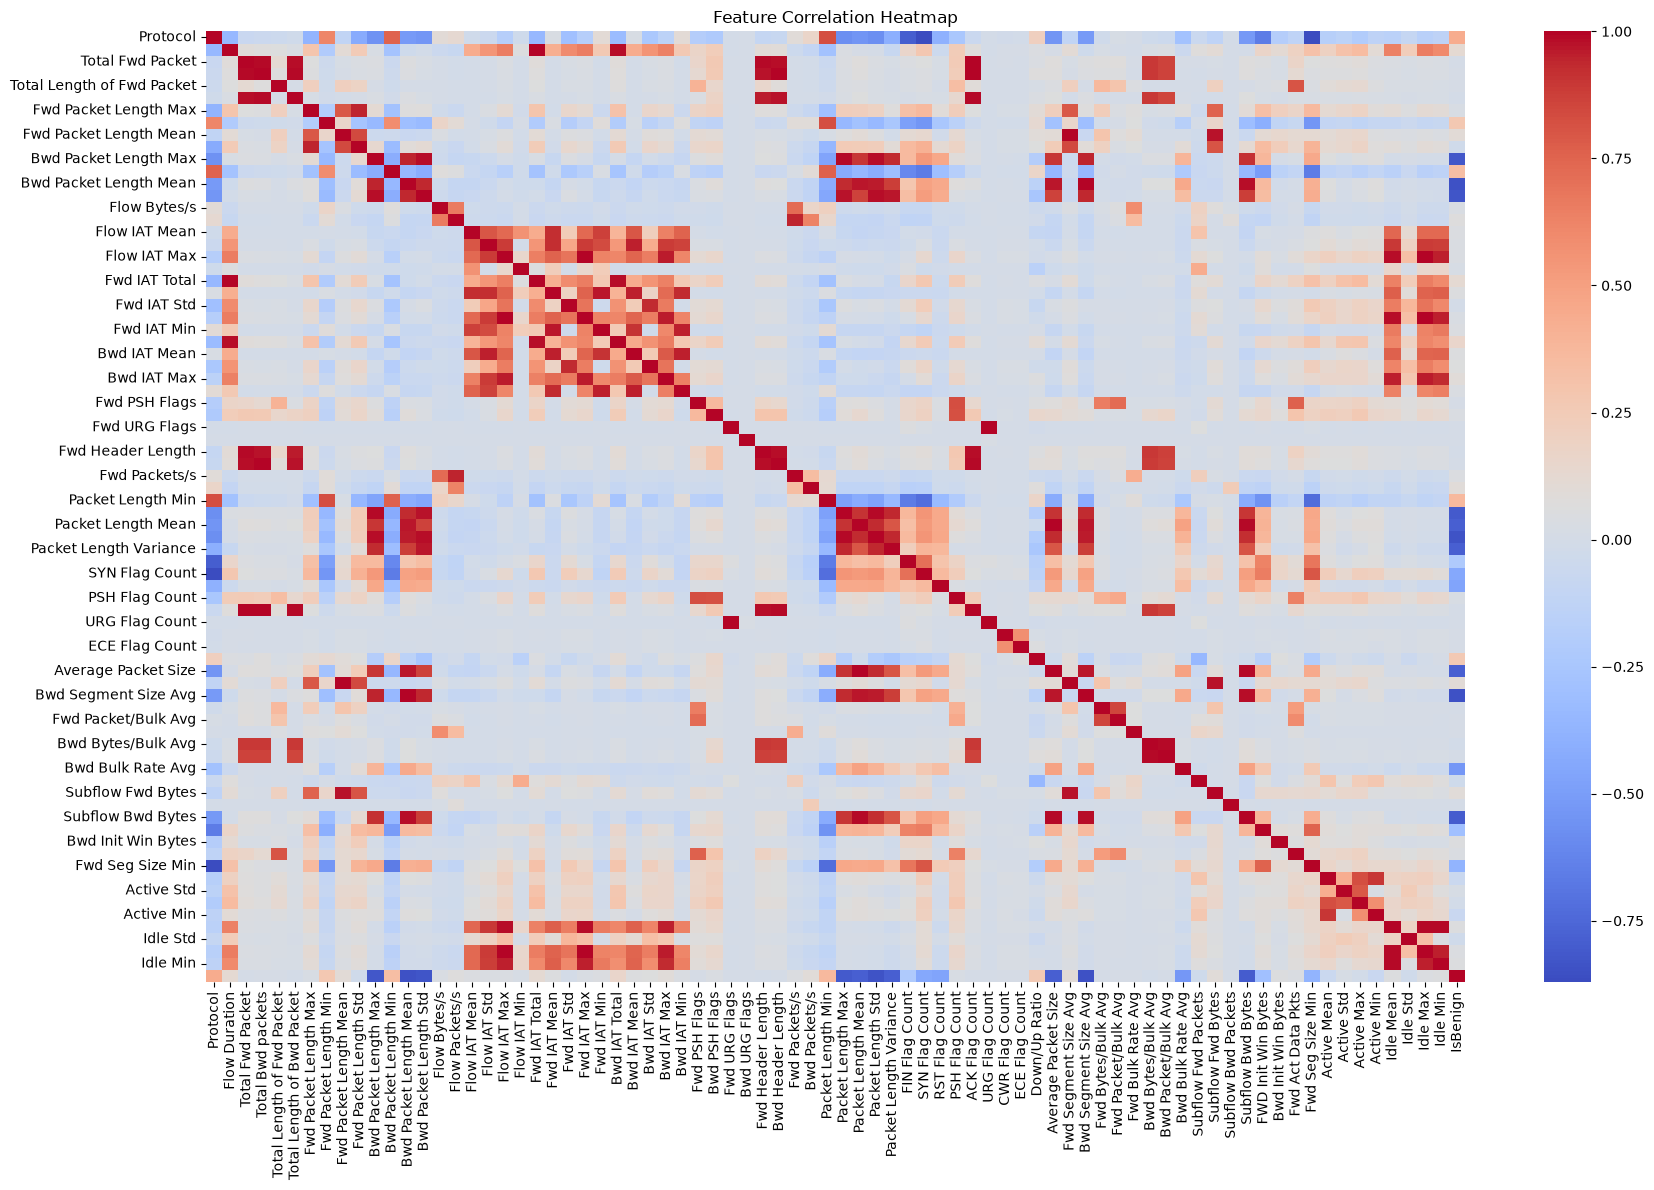

In [130]:
numeric_data = data.select(pl.selectors.numeric())
corr_matrix = numeric_data.corr()


corr_pandas = corr_matrix.to_pandas()


corr_pandas.index = numeric_data.columns

plt.figure(figsize=(18, 12))

sns.heatmap(corr_pandas, annot=False, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [131]:
threshold = 0.95
high_corr = np.where(np.abs(corr_pandas) > threshold)

high_corr = [(corr_pandas.index[x], corr_pandas.columns[y], corr_pandas.iloc[x, y])
                 for x, y in zip(*high_corr) if x != y and x < y]
high_multicollinearity = []
for item in high_corr:
    print(f'{item[0]} has a high correlation with {item[1]}: {item[2].round(4)}')
    if abs(item[2]) >= threshold:
        high_multicollinearity.append(item)


Flow Duration has a high correlation with Fwd IAT Total: 0.9995
Flow Duration has a high correlation with Bwd IAT Total: 0.9826
Total Fwd Packet has a high correlation with Total Bwd packets: 0.9917
Total Fwd Packet has a high correlation with Total Length of Bwd Packet: 0.9809
Total Fwd Packet has a high correlation with Fwd Header Length: 0.9879
Total Fwd Packet has a high correlation with Bwd Header Length: 0.9839
Total Fwd Packet has a high correlation with ACK Flag Count: 0.9962
Total Bwd packets has a high correlation with Total Length of Bwd Packet: 0.9898
Total Bwd packets has a high correlation with Fwd Header Length: 0.976
Total Bwd packets has a high correlation with Bwd Header Length: 0.9937
Total Bwd packets has a high correlation with ACK Flag Count: 0.9985
Total Length of Bwd Packet has a high correlation with Fwd Header Length: 0.9567
Total Length of Bwd Packet has a high correlation with Bwd Header Length: 0.9775
Total Length of Bwd Packet has a high correlation with A

In [ ]:

to_drop = [
    'Fwd IAT Total', 'Bwd IAT Total',

    'Total Bwd packets', 'Total Length of Bwd Packet', 'Fwd Header Length',
    'Bwd Header Length', 'ACK Flag Count',

    'Fwd Segment Size Avg', 'Average Packet Size', 'Bwd Segment Size Avg',

    'Subflow Fwd Bytes',

    'Bwd Packet Length Std', 'Packet Length Max', 'Packet Length Std',

    'Subflow Bwd Bytes', 'Bwd Packet Length Max',

     'Packet Length Variance', 'Fwd Packets/s', 'Fwd IAT Max', 'Bwd IAT Max',
     'Idle Mean', 'Idle Max', 'Idle Min', 'Bwd IAT Min', 'URG Flag Count'
     ,'Bwd Packet/Bulk Avg','Fwd IAT Min', 'Bwd IAT Mean'

]

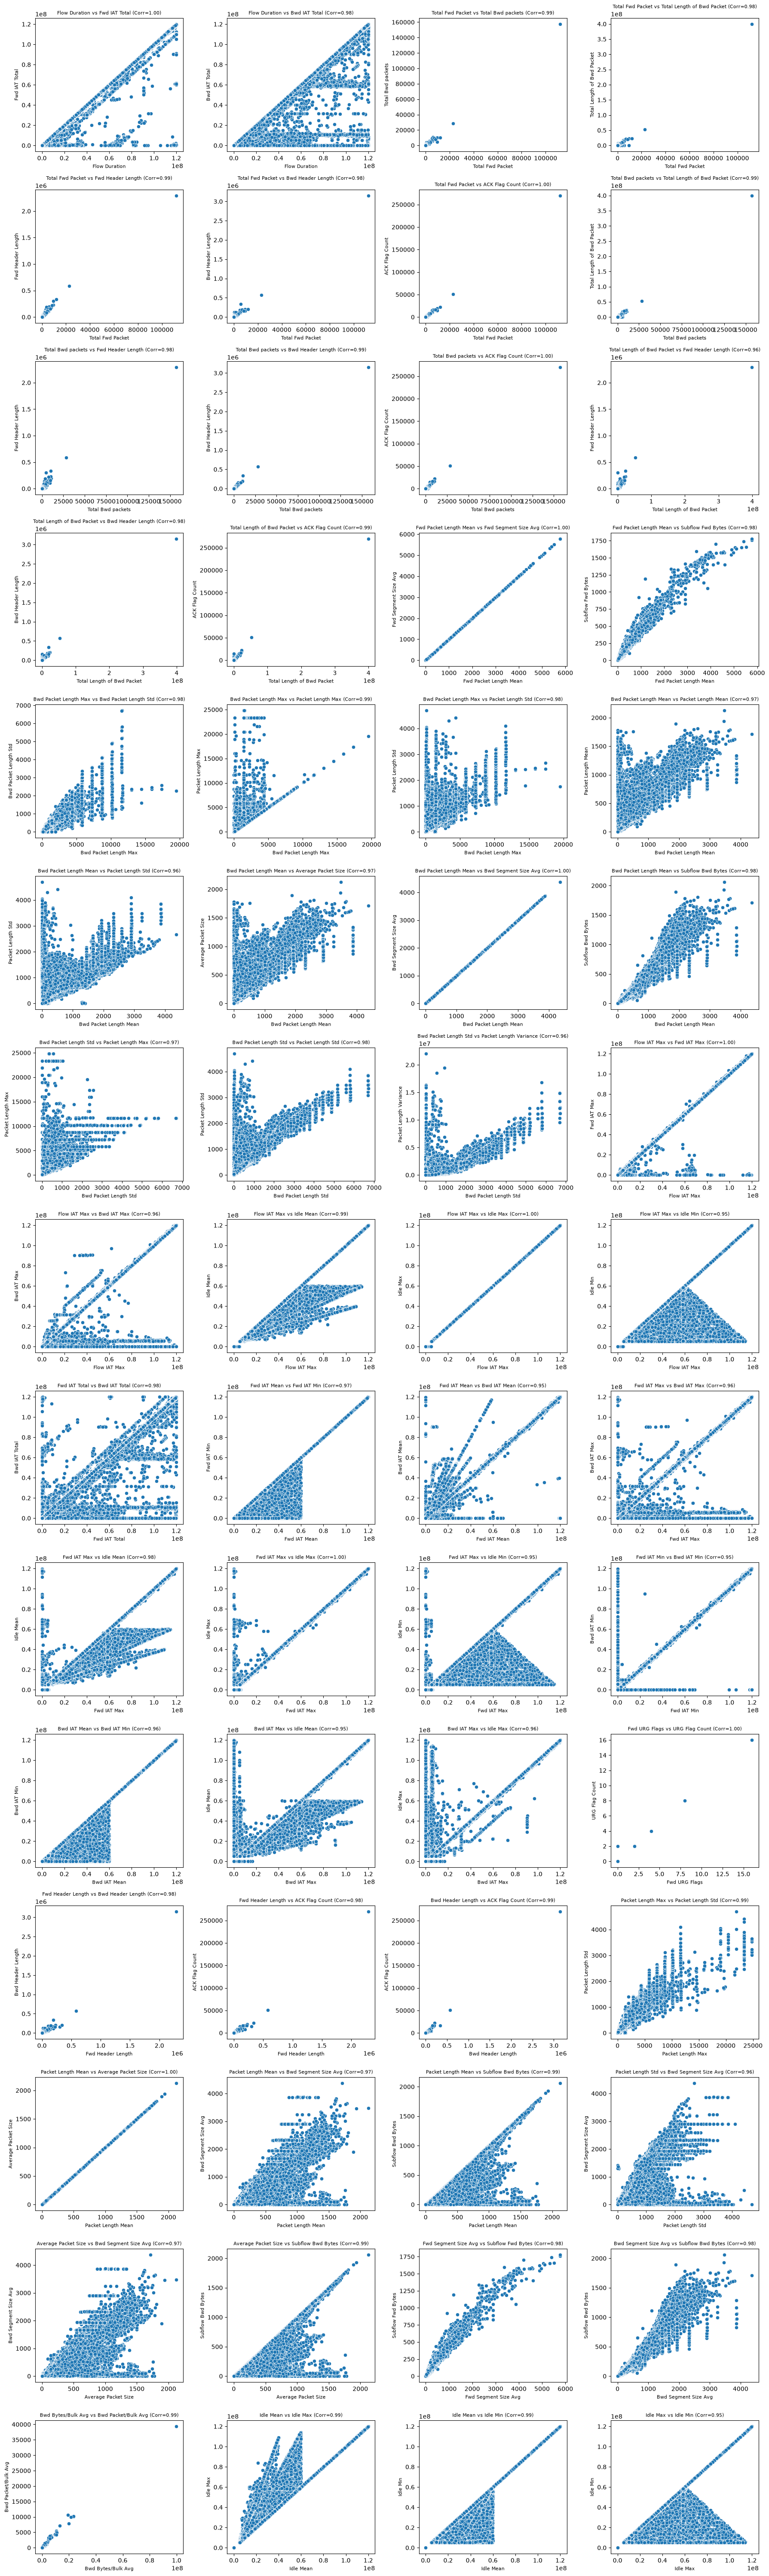

In [133]:

n_plots = len(high_multicollinearity)
n_cols = 4
n_rows = (n_plots + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, item in enumerate(high_multicollinearity):
    feature_x = item[0]
    feature_y = item[1]
    corr_value = item[2]


    sns.scatterplot(x=data[feature_x], y=data[feature_y], ax=axes[i])
    axes[i].set_title(f'{feature_x} vs {feature_y} (Corr={corr_value:.2f})', fontsize=8)
    axes[i].set_xlabel(feature_x, fontsize=8)
    axes[i].set_ylabel(feature_y, fontsize=8)


for j in range(len(high_multicollinearity), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [134]:
data = data.drop(to_drop)

In [135]:
data.shape

(1711447, 51)

In [136]:
data.head()

Protocol,Flow Duration,Total Fwd Packet,Total Length of Fwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Min,Bwd Packet Length Mean,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Mean,Fwd IAT Std,Bwd IAT Std,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Bwd Packets/s,Packet Length Min,Packet Length Mean,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Fwd Bytes/Bulk Avg,Fwd Packet/Bulk Avg,Fwd Bulk Rate Avg,Bwd Bytes/Bulk Avg,Bwd Bulk Rate Avg,Subflow Fwd Packets,Subflow Bwd Packets,FWD Init Win Bytes,Bwd Init Win Bytes,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Std,Label,IsBenign
i32,i32,i32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,i32,i32,i32,i32,f32,f32,f32,i32,i32,i32,i32,i32,i32,f32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,i32,f32,f32,f32,f32,f32,str,i32
6,112740690,32,6448.0,403.0,0.0,201.5,204.724197,72.0,72.0,67.411331,0.425756,2.398738e6,5.798698e6,1.6399772e7,3.0,3636796.5,6.848761e6,8.323385e6,16,16,0,0,0.141919,0.0,158.333328,0,0,0,32,0,0,0.5,0,0,0,0,0,0,0,377,2079,15,32,359.428558,11.998015,380.0,343.0,498804.8125,"""BENIGN""",1
6,112740560,32,6448.0,403.0,0.0,201.5,204.724197,316.0,316.0,102.039589,0.425756,2.3987e6,5798709.5,1.6399782e7,2.0,3.6368e6,6.848777e6,8.323376e6,16,16,0,0,0.141919,0.0,239.666672,0,0,0,32,0,0,0.5,0,0,0,0,0,0,0,955,2079,15,32,320.285706,15.744991,330.0,285.0,498793.65625,"""BENIGN""",1
0,113757377,545,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.790898,209112.828125,1.3955e6,2.075703e7,0.0,209112.828125,1.3955e6,0.0,0,0,0,0,0.0,0.0,0.0,0,0,0,0,0,0,0.0,0,0,0,0,0,1,0,0,0,0,0,9.361829e6,7.324646e6,1.8851792e7,19.0,6.935824e6,"""BENIGN""",1
17,91997219,388,37151.0,227.0,37.0,95.75,55.78532,0.0,0.0,403.827423,4.217519,237718.90625,1.5116e6,1.9776792e7,0.0,237718.90625,1.5116e6,0.0,0,0,0,0,0.0,37.0,95.75,0,0,0,0,0,0,0.0,1857,19,9453,0,0,1,0,0,0,387,8,9.801664e6,1.1527818e7,2.4721964e7,16.0,5826904.5,"""BENIGN""",1
17,66966070,6,288.0,48.0,48.0,48.0,0.0,48.0,48.0,8.601371,0.179195,6087824.5,1.9538234e7,6.4974432e7,191.0,1.3388521e7,2.8861552e7,2.8861632e7,0,0,0,0,0.089598,48.0,48.0,0,0,0,0,0,0,1.0,0,0,0,0,0,0,0,0,0,5,8,1.968172e6,0.0,1.968172e6,1.968172e6,0.0,"""BENIGN""",1


In [137]:
data.shape

(1711447, 51)

In [138]:
data.is_duplicated().sum()

532

* Duplicates appeared again

In [139]:
data = data.unique(keep='first', maintain_order=True)



In [144]:
n_plots = len(data.columns)
n_cols = 2
n_rows = (n_plots + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()
data_pd = data.to_pandas().drop('Label', axis = 1)
for i, column in enumerate(data_pd.columns):
    sns.histplot(data= data_pd, x = column, ax=axes[i])
    axes[i].set_yscale('log')
for j in range(len(data.columns), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [146]:
data.columns

['Protocol',
 'Flow Duration',
 'Total Fwd Packet',
 'Total Length of Fwd Packet',
 'Fwd Packet Length Max',
 'Fwd Packet Length Min',
 'Fwd Packet Length Mean',
 'Fwd Packet Length Std',
 'Bwd Packet Length Min',
 'Bwd Packet Length Mean',
 'Flow Bytes/s',
 'Flow Packets/s',
 'Flow IAT Mean',
 'Flow IAT Std',
 'Flow IAT Max',
 'Flow IAT Min',
 'Fwd IAT Mean',
 'Fwd IAT Std',
 'Bwd IAT Std',
 'Fwd PSH Flags',
 'Bwd PSH Flags',
 'Fwd URG Flags',
 'Bwd URG Flags',
 'Bwd Packets/s',
 'Packet Length Min',
 'Packet Length Mean',
 'FIN Flag Count',
 'SYN Flag Count',
 'RST Flag Count',
 'PSH Flag Count',
 'CWR Flag Count',
 'ECE Flag Count',
 'Down/Up Ratio',
 'Fwd Bytes/Bulk Avg',
 'Fwd Packet/Bulk Avg',
 'Fwd Bulk Rate Avg',
 'Bwd Bytes/Bulk Avg',
 'Bwd Bulk Rate Avg',
 'Subflow Fwd Packets',
 'Subflow Bwd Packets',
 'FWD Init Win Bytes',
 'Bwd Init Win Bytes',
 'Fwd Act Data Pkts',
 'Fwd Seg Size Min',
 'Active Mean',
 'Active Std',
 'Active Max',
 'Active Min',
 'Idle Std',
 'Label',
 'I